# 06 — Interprétation des modèles (version simple)

**Objectif** : comprendre ce que les modèles ont retenu, avec trois outils simples et sans bibliothèque supplémentaire.

| Outil | Question à laquelle il répond |
|---|---|
| **1. Importance par permutation** | Quelles variables comptent le plus pour prédire ? |
| **2. Effet moyen d'une variable** | Quand cette variable change, comment évolue la prédiction « toutes choses égales par ailleurs » ? |
| **3. Explication d'un logement** | Pourquoi ce logement-ci a-t-il cette consommation prédite, par rapport à un logement de référence ? |

On interprète les deux modèles déjà enregistrés : la **régression** (consommation en kWhEP/m²/an) et la **classification** (étiquette A à G).

## 0. Préparation

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

from src.utilis import config

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4.5)

DOSSIER_FIG = config.RACINE / "reports" / "figures"
ETIQ, CONSO = config.CIBLE_CLASSIFICATION, config.CIBLE_REGRESSION
ORDRE = config.ORDRE_ETIQUETTES
GRAINE = config.GRAINE_ALEATOIRE
N_REPETITIONS = 5     # nombre de mélanges par variable (importance par permutation)
TAILLE_ECHANTILLON = 1500   # logements utilisés pour les effets moyens (rapidité)


def sauver(fig, nom):
    DOSSIER_FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(DOSSIER_FIG / f"{nom}.png", dpi=150, bbox_inches="tight")

## 1. Chargement des modèles et des données

In [3]:
train = pd.read_csv(config.DATA_TRAITE / "train.csv", low_memory=False)
test = pd.read_csv(config.DATA_TRAITE / "test.csv", low_memory=False)
with open(config.DOSSIER_MODELES / "variables_retenues.json", encoding="utf-8") as f:
    decisions = json.load(f)
VARS_NUMERIQUES = set(decisions["variables_numeriques"])

for d in (train, test):
    d["conso_aberrante"] = d["conso_aberrante"].astype(str).str.lower().eq("true")
train_r = train.loc[~train["conso_aberrante"]]
test_r = test.loc[~test["conso_aberrante"]].reset_index(drop=True)

chemin_cls = config.DOSSIER_MODELES / "modele_classification.joblib"
chemins_reg = [config.DOSSIER_MODELES / "modele_regression.joblib",
               config.DOSSIER_MODELES / "modele_regression_consommation.joblib"]
chemin_reg = next((c for c in chemins_reg if c.exists()), None)
assert chemin_cls.exists() and chemin_reg is not None, "modèles introuvables : exécuter les notebooks 03 et 04"

modele_cls = joblib.load(chemin_cls)
modele_reg = joblib.load(chemin_reg)

# Les variables sont lues dans les modèles eux-mêmes : on interprète ce qu'ils ont réellement reçu.
vars_cls = list(modele_cls.feature_names_in_)
vars_reg = list(modele_reg.feature_names_in_)
print(f"Classification : {type(modele_cls.named_steps['modele']).__name__}, {len(vars_cls)} variables")
print(f"Régression     : {type(modele_reg.named_steps['modele']).__name__}, {len(vars_reg)} variables")
print(f"Test : {len(test):,} lignes (classification), {len(test_r):,} lignes (régression, sans consommations aberrantes)")

Classification : RandomForestClassifier, 23 variables
Régression     : HistGradientBoostingRegressor, 23 variables
Test : 9,839 lignes (classification), 9,839 lignes (régression, sans consommations aberrantes)


## 2. Importance par permutation
**Principe** : on prend le jeu de test, on **mélange au hasard les valeurs d'une seule variable** (ce qui détruit son lien avec la cible), et on mesure de combien le modèle se dégrade. Plus la dégradation est grande, plus la variable compte. On répète 5 fois et on garde la moyenne.

- Pour la régression : hausse de l'erreur moyenne (MAE, en kWhEP/m²/an).
- Pour la classification : baisse du F1 macro.

**Limite** : si deux variables portent la même information, mélanger l'une est compensé par l'autre : leur importance paraît alors sous-estimée.

In [4]:
perm_reg = permutation_importance(modele_reg, test_r[vars_reg], test_r[CONSO],
                                  scoring="neg_mean_absolute_error", n_repeats=N_REPETITIONS,
                                  random_state=GRAINE, n_jobs=-1)
perm_cls = permutation_importance(modele_cls, test[vars_cls], test[ETIQ],
                                  scoring="f1_macro", n_repeats=N_REPETITIONS,
                                  random_state=GRAINE, n_jobs=-1)

importance = pd.DataFrame(index=sorted(set(vars_reg) | set(vars_cls)))
importance["regression_hausse_mae"] = pd.Series(perm_reg.importances_mean, index=vars_reg)
importance["regression_ecart_type"] = pd.Series(perm_reg.importances_std, index=vars_reg)
importance["classification_baisse_f1"] = pd.Series(perm_cls.importances_mean, index=vars_cls)
importance["classification_ecart_type"] = pd.Series(perm_cls.importances_std, index=vars_cls)

# Part de l'importance totale (hors valeurs négatives dues au hasard)
for colonne in ["regression_hausse_mae", "classification_baisse_f1"]:
    positif = importance[colonne].clip(lower=0)
    importance[colonne.replace("hausse_mae", "part").replace("baisse_f1", "part")] = positif / positif.sum()

importance = importance.sort_values("regression_hausse_mae", ascending=False)
importance

,regression_hausse_mae,regression_ecart_type,classification_baisse_f1,classification_ecart_type,regression_part,classification_part
surface_habitable_logement,8.323,0.090,0.013,0.002,0.132,0.032
type_generateur_n1_ecs_n1,7.815,0.112,0.082,0.003,0.124,0.196
annee_construction,5.833,0.105,0.036,0.002,0.093,0.086
type_generateur_n1_installation_n1,5.543,0.135,0.011,0.003,0.088,0.026
qualite_isolation_murs,4.891,0.111,0.043,0.004,0.078,0.102
qualite_isolation_enveloppe,4.733,0.111,0.019,0.002,0.075,0.047
type_emetteur_installation_chauffage_n1,3.598,0.059,0.017,0.003,0.057,0.040
type_installation_ecs,3.047,0.081,0.015,0.002,0.048,0.036
surface_chauffee_installation_chauffage_n1,2.915,0.112,0.019,0.002,0.046,0.046
type_generateur_froid,2.635,0.048,0.064,0.003,0.042,0.153


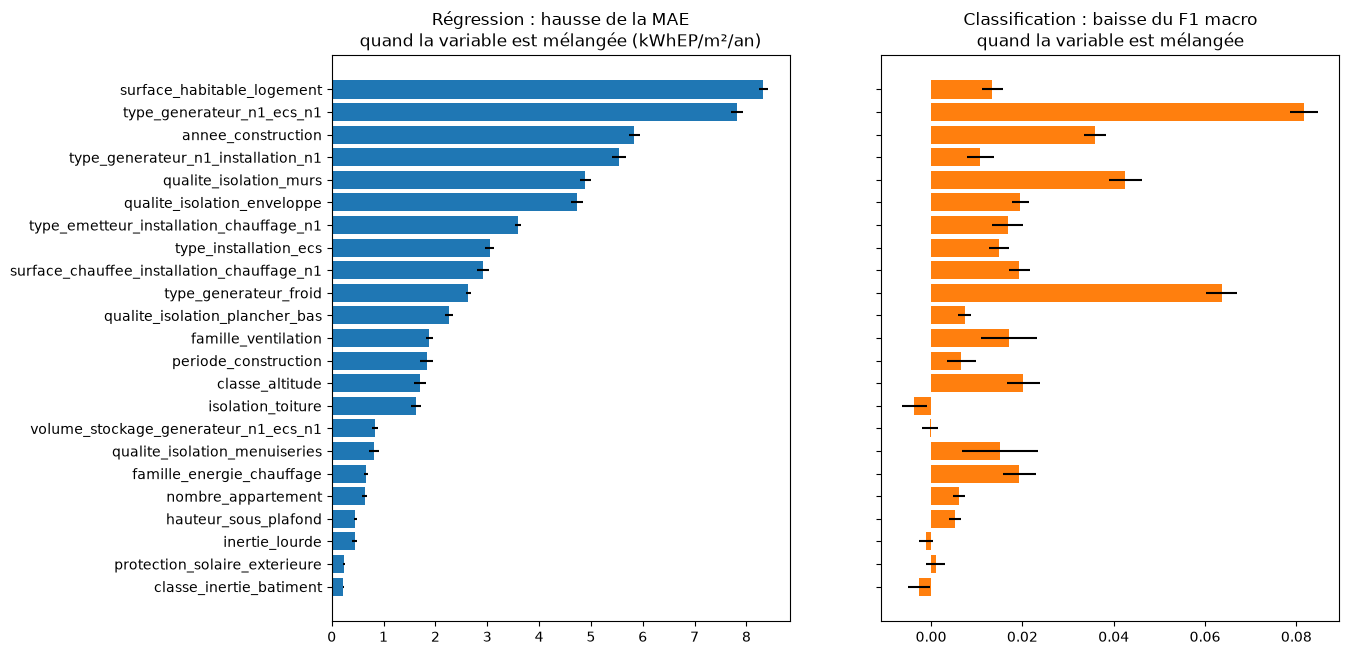

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, max(4.5, 0.32 * len(importance))), sharey=True)
ordre = importance.sort_values("regression_hausse_mae").index
axes[0].barh(ordre, importance.loc[ordre, "regression_hausse_mae"],
             xerr=importance.loc[ordre, "regression_ecart_type"])
axes[0].set_title("Régression : hausse de la MAE\nquand la variable est mélangée (kWhEP/m²/an)")
axes[1].barh(ordre, importance.loc[ordre, "classification_baisse_f1"],
             xerr=importance.loc[ordre, "classification_ecart_type"], color="tab:orange")
axes[1].set_title("Classification : baisse du F1 macro\nquand la variable est mélangée")
sauver(fig, "06_importance_permutation")
plt.show()

**Lecture** : les barres d'erreur sont l'écart-type des 5 mélanges. Une barre qui touche zéro signifie que la variable n'apporte rien de mesurable à ce modèle. Si les deux modèles classent les variables à peu près dans le même ordre, c'est un signe de cohérence : ils s'appuient sur les mêmes informations.

## 3. Effet moyen d'une variable 
**Principe** : pour une variable donnée, on impose à **tous** les logements de l'échantillon la même valeur, on prédit, et on fait la moyenne. On recommence pour plusieurs valeurs. La courbe obtenue montre comment la prédiction moyenne évolue quand seule cette variable change, les autres gardant leurs valeurs réelles.

- Variable numérique : une courbe sur 10 valeurs (du 5ᵉ au 95ᵉ centile).
- Variable catégorielle : une barre par modalité fréquente (au moins 2 % des logements).

On étudie les **6 variables les plus importantes** pour la régression.

In [7]:
echantillon = test_r.sample(min(TAILLE_ECHANTILLON, len(test_r)), random_state=GRAINE)
X_ech = echantillon[vars_reg]
top_variables = list(importance.index[:6])


def valeurs_a_tester(variable):
    serie = X_ech[variable].dropna()
    if variable in VARS_NUMERIQUES:
        return list(np.unique(np.quantile(serie, np.linspace(0.05, 0.95, 10)).round(2)))
    parts = serie.value_counts(normalize=True)
    return list(parts[parts >= 0.02].index[:8])


def effet_moyen(modele, X, variable, valeurs, mesure):
    sorties = []
    for valeur in valeurs:
        X_mod = X.copy()
        X_mod[variable] = valeur
        sorties.append(mesure(modele, X_mod))
    return np.array(sorties)


def mesure_conso(modele, X):
    return float(modele.predict(X).mean())


effets_conso = {}
for variable in top_variables:
    valeurs = valeurs_a_tester(variable)
    effets_conso[variable] = (valeurs, effet_moyen(modele_reg, X_ech, variable, valeurs, mesure_conso))
print(f"Consommation prédite moyenne de l'échantillon : {mesure_conso(modele_reg, X_ech):.1f} kWhEP/m²/an")

Consommation prédite moyenne de l'échantillon : 143.5 kWhEP/m²/an


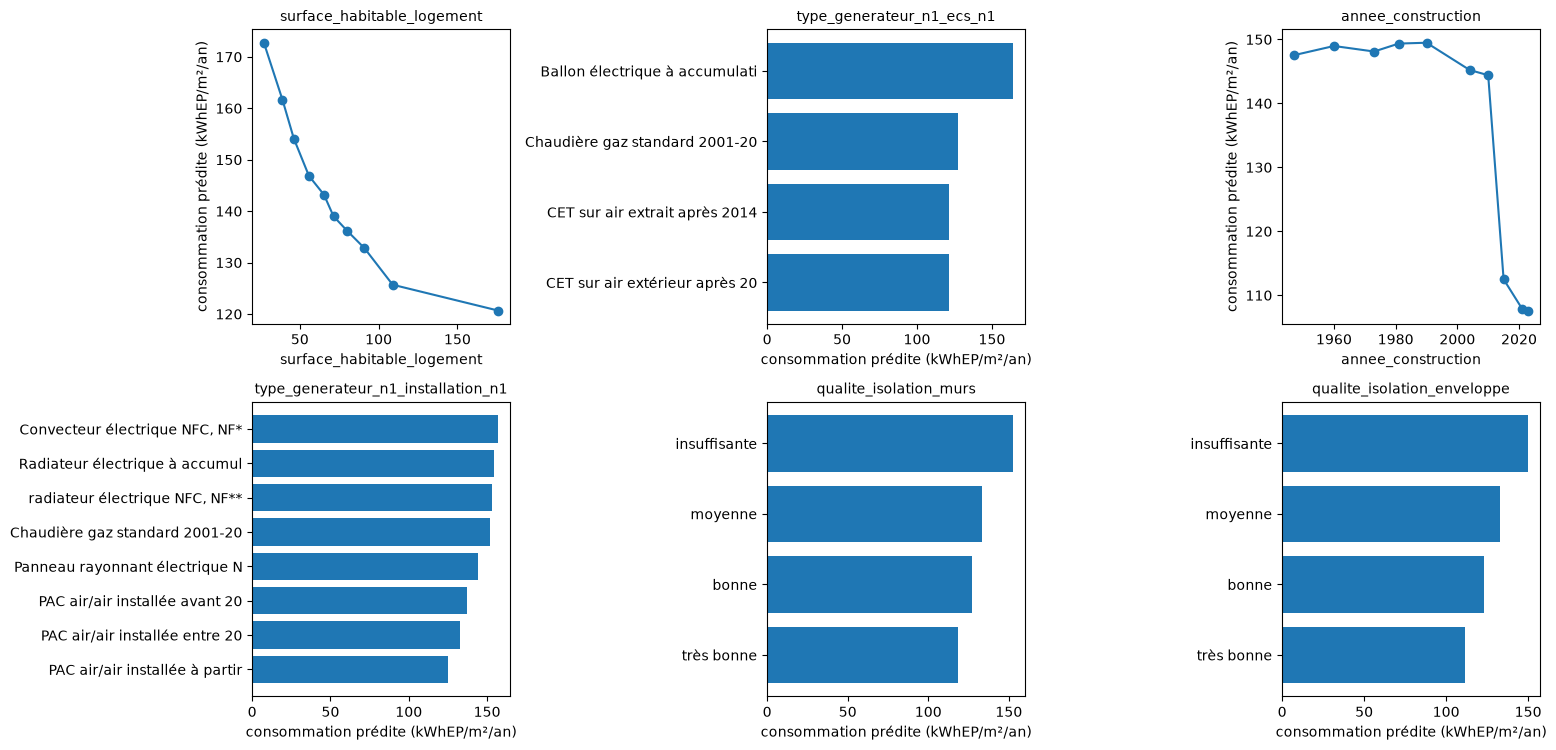

In [8]:
def tracer(effets, titre_y, nom_figure):
    n = len(effets)
    colonnes = 3
    lignes = int(np.ceil(n / colonnes))
    fig, axes = plt.subplots(lignes, colonnes, figsize=(5.2 * colonnes, 3.8 * lignes))
    axes = np.atleast_1d(axes).ravel()
    for ax, (variable, (valeurs, y)) in zip(axes, effets.items()):
        if variable in VARS_NUMERIQUES:
            ax.plot(valeurs, y, marker="o")
            ax.set_xlabel(variable)
            ax.set_ylabel(titre_y)
        else:
            ordre_barres = np.argsort(y)
            ax.barh([str(valeurs[i])[:30] for i in ordre_barres], y[ordre_barres])
            ax.set_xlabel(titre_y)
        ax.set_title(variable, fontsize=10)
    for ax in axes[n:]:
        ax.axis("off")
    fig.tight_layout()
    sauver(fig, nom_figure)
    plt.show()


tracer(effets_conso, "consommation prédite (kWhEP/m²/an)", "06_effets_moyens_consommation")

In [10]:
def phrase(variable, valeurs, y, unite, d=0):
    if variable in VARS_NUMERIQUES:
        return (f"{variable} : de {valeurs[0]} à {valeurs[-1]}, la {unite} prédite moyenne passe de "
                f"{y[0]:.{d}f} à {y[-1]:.{d}f}")
    bas, haut = int(np.argmin(y)), int(np.argmax(y))
    return (f"{variable} : la plus faible pour « {str(valeurs[bas])[:40]} » ({y[bas]:.{d}f}), "
            f"la plus forte pour « {str(valeurs[haut])[:40]} » ({y[haut]:.{d}f})")


print("Résumé en phrases  :\n")
for variable, (valeurs, y) in effets_conso.items():
    print("-", phrase(variable, valeurs, y, "consommation"))

Résumé en phrases  :

- surface_habitable_logement : de 27.2 à 175.9, la consommation prédite moyenne passe de 173 à 121
- type_generateur_n1_ecs_n1 : la plus faible pour « CET sur air extérieur après 2014 » (121), la plus forte pour « Ballon électrique à accumulation horizon » (164)
- annee_construction : de 1947.0 à 2023.0, la consommation prédite moyenne passe de 148 à 108
- type_generateur_n1_installation_n1 : la plus faible pour « PAC air/air installée à partir de 2015 » (125), la plus forte pour « Convecteur électrique NFC, NF** et NF*** » (157)
- qualite_isolation_murs : la plus faible pour « très bonne » (118), la plus forte pour « insuffisante » (152)
- qualite_isolation_enveloppe : la plus faible pour « très bonne » (112), la plus forte pour « insuffisante » (150)


### 3.1 Même analyse pour la classification : la part de « passoires » (F ou G)
Pour la classification, on suit la **probabilité moyenne que le logement soit classé F ou G**, ce qui répond à l'enjeu pratique : quelles caractéristiques font basculer vers une passoire énergétique ?

Probabilité moyenne F ou G dans l'échantillon : 6.7%


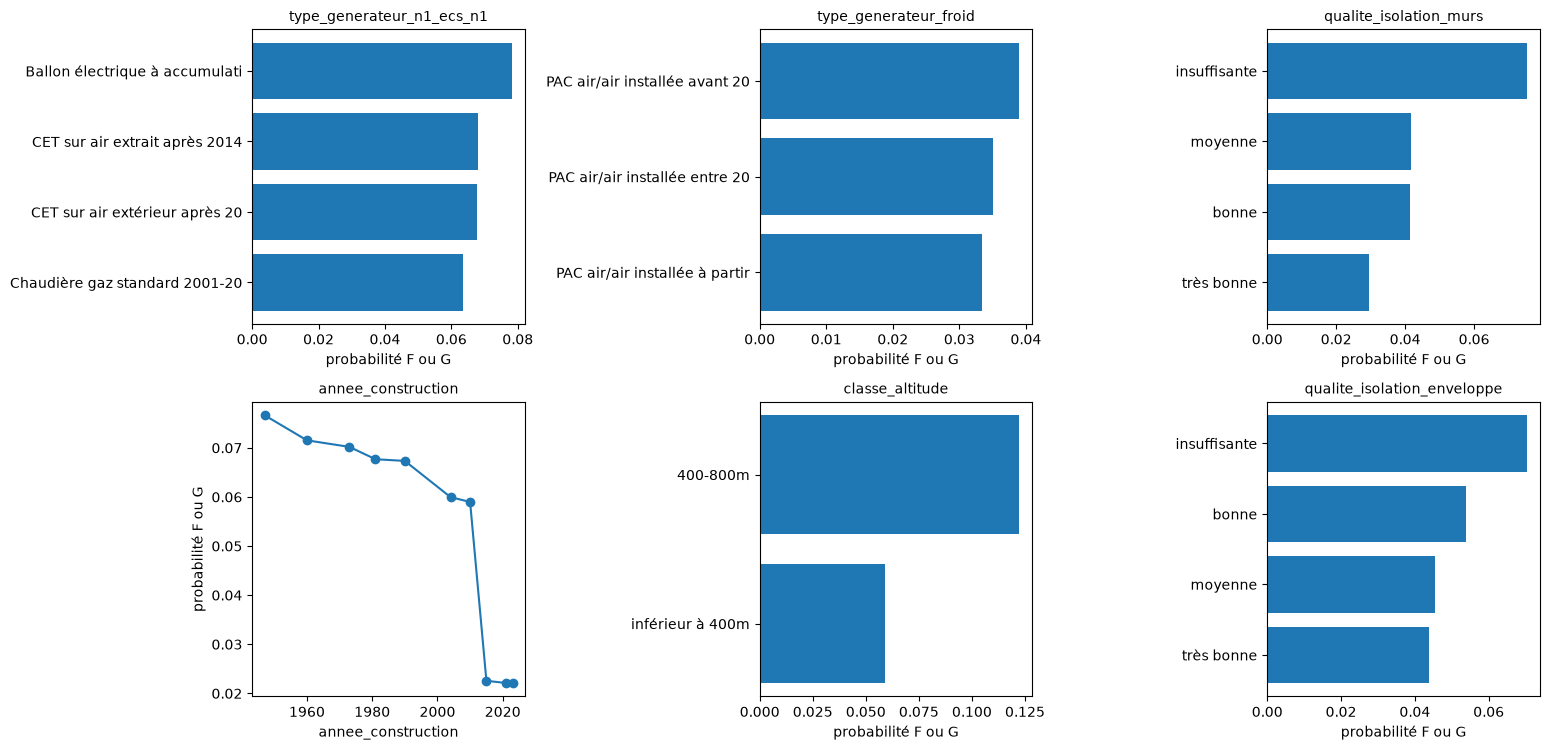

- type_generateur_n1_ecs_n1 : la plus faible pour « Chaudière gaz standard 2001-2015 » (6.3), la plus forte pour « Ballon électrique à accumulation horizon » (7.8)
- type_generateur_froid : la plus faible pour « PAC air/air installée à partir de 2015 » (3.3), la plus forte pour « PAC air/air installée avant 2008 » (3.9)
- qualite_isolation_murs : la plus faible pour « très bonne » (3.0), la plus forte pour « insuffisante » (7.5)
- annee_construction : de 1947.0 à 2023.0, la probabilité (en %) F ou G prédite moyenne passe de 7.7 à 2.2
- classe_altitude : la plus faible pour « inférieur à 400m » (5.9), la plus forte pour « 400-800m » (12.2)
- qualite_isolation_enveloppe : la plus faible pour « très bonne » (4.4), la plus forte pour « insuffisante » (7.0)


In [11]:
classes_cls = list(modele_cls.classes_)


def mesure_passoire(modele, X):
    proba = modele.predict_proba(X)
    return float(proba[:, [classes_cls.index("F"), classes_cls.index("G")]].sum(axis=1).mean())


X_ech_cls = test.sample(min(TAILLE_ECHANTILLON, len(test)), random_state=GRAINE)[vars_cls]
top_cls = [v for v in importance.sort_values("classification_baisse_f1", ascending=False).index
           if v in vars_cls][:6]


def valeurs_cls(variable):
    serie = X_ech_cls[variable].dropna()
    if variable in VARS_NUMERIQUES:
        return list(np.unique(np.quantile(serie, np.linspace(0.05, 0.95, 10)).round(2)))
    parts = serie.value_counts(normalize=True)
    return list(parts[parts >= 0.02].index[:8])


effets_passoire = {}
for variable in top_cls:
    valeurs = valeurs_cls(variable)
    effets_passoire[variable] = (valeurs, effet_moyen(modele_cls, X_ech_cls, variable, valeurs, mesure_passoire))

print(f"Probabilité moyenne F ou G dans l'échantillon : {mesure_passoire(modele_cls, X_ech_cls):.1%}")
tracer(effets_passoire, "probabilité F ou G", "06_effets_moyens_passoires")
for variable, (valeurs, y) in effets_passoire.items():
    print("-", phrase(variable, valeurs, y * 100, "probabilité (en %) F ou G", d=1))

## 4. Explication d'un logement
**Principe** : on part d'un **logement de référence** (la valeur médiane pour les variables numériques, la modalité la plus fréquente pour les catégorielles). Pour un logement donné, on remplace **une variable à la fois** par sa valeur de référence et on regarde de combien la consommation prédite change. Une contribution **positive** signifie que la valeur réelle de la variable augmente la consommation par rapport à la référence.

C'est une approximation (elle ignore les interactions entre variables) : le tableau affiche donc l'écart total et la somme des contributions, qui ne sont pas strictement égaux.

In [12]:
reference = {}
for variable in vars_reg:
    if variable in VARS_NUMERIQUES:
        reference[variable] = float(train_r[variable].median())
    else:
        reference[variable] = train_r[variable].mode().iloc[0]
ligne_reference = pd.DataFrame([reference])[vars_reg]
pred_reference = float(modele_reg.predict(ligne_reference)[0])
print(f"Logement de référence : consommation prédite {pred_reference:.1f} kWhEP/m²/an")
print(pd.Series(reference).to_string())

Logement de référence : consommation prédite 129.0 kWhEP/m²/an
annee_construction                                                                    2,000.000
surface_habitable_logement                                                               67.700
surface_chauffee_installation_chauffage_n1                                               62.600
hauteur_sous_plafond                                                                      2.500
volume_stockage_generateur_n1_ecs_n1                                                    150.000
nombre_appartement                                                                        1.000
famille_ventilation                                                                    fenetres
type_generateur_froid                                    PAC air/air installée à partir de 2015
qualite_isolation_murs                                                             insuffisante
type_generateur_n1_ecs_n1                     Ballon électrique à accumul

In [13]:
pred_test = pd.Series(modele_reg.predict(test_r[vars_reg]), index=test_r.index)


def expliquer(ligne, titre):
    X_ligne = ligne[vars_reg].to_frame().T.infer_objects()
    pred = float(modele_reg.predict(X_ligne)[0])
    lignes = []
    for variable in vars_reg:
        X_mod = X_ligne.copy()
        X_mod[variable] = reference[variable]
        lignes.append({"variable": variable, "valeur_du_logement": X_ligne[variable].iloc[0],
                       "valeur_de_reference": reference[variable],
                       "contribution": pred - float(modele_reg.predict(X_mod)[0])})
    tab_c = pd.DataFrame(lignes).sort_values("contribution", key=abs, ascending=False)
    print(f"=== {titre} ===")
    print(f"Consommation réelle {ligne[CONSO]:.0f} | prédite {pred:.0f} | référence {pred_reference:.0f}")
    print(f"Écart total par rapport à la référence : {pred - pred_reference:+.0f} | "
          f"somme des contributions : {tab_c['contribution'].sum():+.0f}")
    display(tab_c.head(8).set_index("variable"))
    return tab_c


exemples = {}
for etiquette in ["A", "C", "F"]:
    sous = test_r[test_r[ETIQ] == etiquette]
    if len(sous):
        ecarts = (pred_test.loc[sous.index] - sous[CONSO]).abs()
        exemples[etiquette] = sous.loc[ecarts.idxmin()]   # logement bien prédit de cette étiquette

explications = {et: expliquer(l, f"Logement d'étiquette {et} (bien prédit)") for et, l in exemples.items()}

=== Logement d'étiquette A (bien prédit) ===
Consommation réelle 40 | prédite 40 | référence 129
Écart total par rapport à la référence : -89 | somme des contributions : -149


,valeur_du_logement,valeur_de_reference,contribution
variable,,,
annee_construction,"2,022.000","2,000.000",-68.585
type_generateur_n1_ecs_n1,NaN,Ballon électrique à accumulation vertical Caté...,-54.696
qualite_isolation_murs,très bonne,insuffisante,-28.449
type_generateur_n1_installation_n1,NaN,PAC air/air installée à partir de 2015,10.430
qualite_isolation_menuiseries,très bonne,moyenne,-8.985
type_emetteur_installation_chauffage_n1,NaN,Soufflage d'air chaud (air soufflé) avec distr...,8.246
nombre_appartement,45.000,1.000,-7.411
isolation_toiture,NaN,0.000,-7.099


=== Logement d'étiquette C (bien prédit) ===
Consommation réelle 170 | prédite 170 | référence 129
Écart total par rapport à la référence : +41 | somme des contributions : -20


,valeur_du_logement,valeur_de_reference,contribution
variable,,,
surface_chauffee_installation_chauffage_n1,5.200,62.600,-62.973
qualite_isolation_murs,bonne,insuffisante,-33.991
type_generateur_n1_ecs_n1,Ballon électrique à accumulation horizontal,Ballon électrique à accumulation vertical Caté...,23.962
surface_habitable_logement,40.400,67.700,23.477
qualite_isolation_plancher_bas,bonne,très bonne,15.668
isolation_toiture,1.000,0.000,13.543
type_generateur_n1_installation_n1,Autres émetteurs à effet joule,PAC air/air installée à partir de 2015,8.233
type_generateur_froid,PAC air/air installée entre 2008 et 2014,PAC air/air installée à partir de 2015,8.157


=== Logement d'étiquette F (bien prédit) ===
Consommation réelle 385 | prédite 384 | référence 129
Écart total par rapport à la référence : +255 | somme des contributions : +460


,valeur_du_logement,valeur_de_reference,contribution
variable,,,
type_emetteur_installation_chauffage_n1,Poêle bois,Soufflage d'air chaud (air soufflé) avec distr...,105.449
type_generateur_froid,NaN,PAC air/air installée à partir de 2015,76.916
famille_energie_chauffage,bois,electricite,73.145
surface_habitable_logement,34.100,67.700,68.323
qualite_isolation_menuiseries,insuffisante,moyenne,48.024
qualite_isolation_plancher_bas,insuffisante,très bonne,45.637
classe_inertie_batiment,Légère,Moyenne,33.962
type_generateur_n1_ecs_n1,Ballon électrique à accumulation vertical Autr...,Ballon électrique à accumulation vertical Caté...,15.967


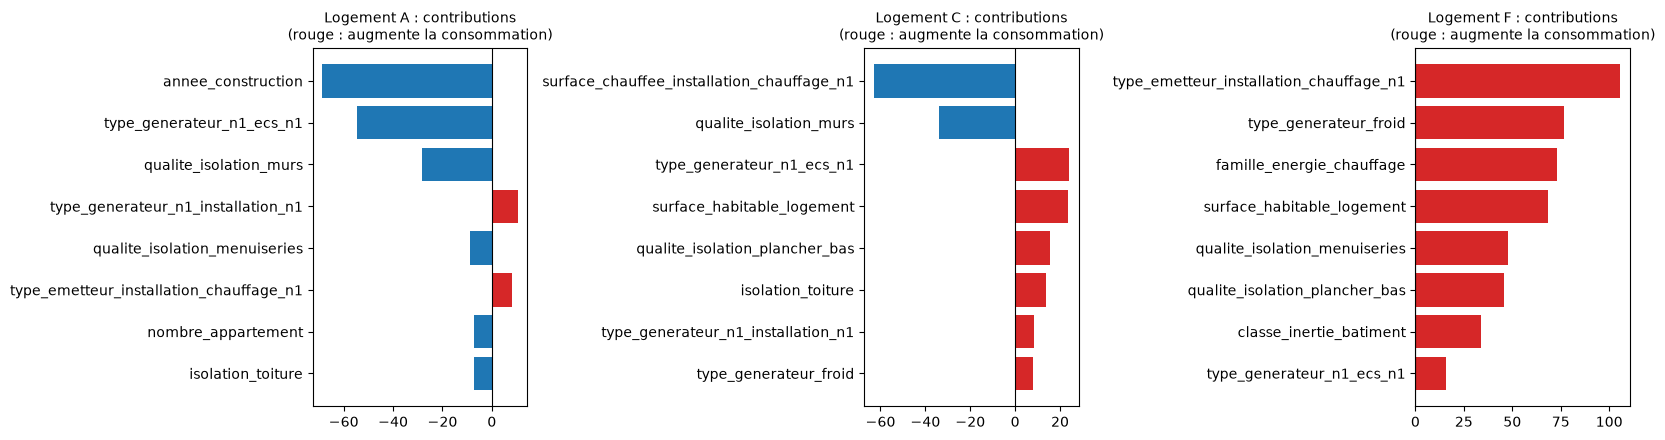

In [14]:
fig, axes = plt.subplots(1, len(explications), figsize=(5.5 * len(explications), 4.5))
for ax, (etiquette, tab_c) in zip(np.atleast_1d(axes), explications.items()):
    top = tab_c.head(8).iloc[::-1]
    ax.barh(top["variable"], top["contribution"],
            color=["tab:red" if c > 0 else "tab:blue" for c in top["contribution"]])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Logement {etiquette} : contributions\n(rouge : augmente la consommation)", fontsize=10)
fig.tight_layout()
sauver(fig, "06_explication_logements")
plt.show()

## 5. Sauvegarde

In [15]:
config.DATA_TRAITE.mkdir(parents=True, exist_ok=True)
importance.to_csv(config.DATA_TRAITE / "interpretation_importance.csv")

lignes_effets = []
for tache, effets in [("consommation", effets_conso), ("passoires_F_G", effets_passoire)]:
    for variable, (valeurs, y) in effets.items():
        for valeur, resultat in zip(valeurs, y):
            lignes_effets.append({"tache": tache, "variable": variable, "valeur": valeur, "prediction_moyenne": resultat})
pd.DataFrame(lignes_effets).to_csv(config.DATA_TRAITE / "interpretation_effets_moyens.csv", index=False)
print("Fichiers écrits : interpretation_importance.csv, interpretation_effets_moyens.csv et les figures 06_*.png")

Fichiers écrits : interpretation_importance.csv, interpretation_effets_moyens.csv et les figures 06_*.png


## 6. Synthèse et limites

**Limites à écrire dans le rapport**
- Ces outils décrivent ce que le **modèle** a appris, pas des causes réelles ni l'effet d'une rénovation. Ils ne prouvent pas, par exemple, qu'améliorer l'isolation d'un niveau réduirait la consommation du montant observé.
- Les variables sont **corrélées** entre elles (période de construction, ventilation, type de générateur) : l'importance se partage entre elles, et un effet « toutes choses égales par ailleurs » peut décrire des combinaisons peu réalistes.
- Les modèles prédisent des valeurs **conventionnelles** du DPE : ils reflètent la méthode de calcul, pas la consommation réelle des habitants.
- L'explication d'un logement est une approximation qui ignore les interactions.